[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_hist_qq/BA_L2_hist_qq.ipynb)

# BA_L2_hist_qq: Fit of the Normal Distribution

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Histogram of Bitcoin daily log returns against the Normal density with the same mean and standard deviation, and Normal QQ plots of Bitcoin and S&P 500 standardised returns, 1 January 2018 to 18 September 2026, with moments and the Jarque-Bera test.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

Daily log returns in percent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$, from 1 January 2018 to 18 September 2026 (EODHD
closes). Crypto trades every day; for the S&P 500 and gold only Monday–Friday closes are kept and repeated closes
(holidays filled with the last price) are removed.

The sample skewness and excess kurtosis are $\hat S = \frac1n\sum_t z_t^3$ and $\hat K = \frac1n\sum_t z_t^4 - 3$,
with $z_t = (r_t - \bar r)/s$; both are 0 for the Normal distribution. The **Jarque–Bera** (JB) test,
$\mathrm{JB} = \frac{n}{6}\big(\hat S^2 + \hat K^2/4\big) \sim \chi^2_2$ under normality, rejects at 5% above 5.99.

A **QQ plot** draws the sorted standardised returns against the Normal quantiles $\Phi^{-1}\big((i - 0.5)/n\big)$;
Normal data lie on the 45-degree line.

**How to read the chart.** Left: too many quiet days in the centre and too many extreme days, too few in between
(returns beyond ±20% are drawn at ±20%). Middle and right: both QQ plots bend away from the red line at the ends,
the signature of heavy tails, in crypto and in equities.

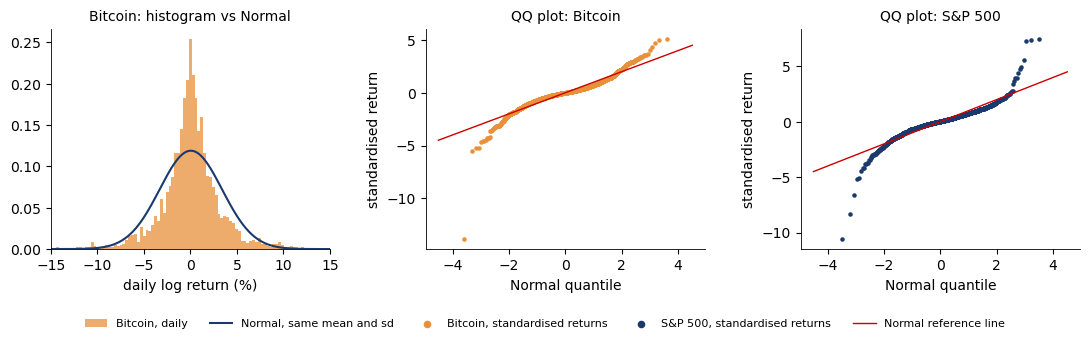

In [5]:
from scipy import stats

ASSETS = {'Bitcoin': ('BTC-USD.CC', 365), 'Ethereum': ('ETH-USD.CC', 365), 'S&P 500': ('GSPC.INDX', 252), 'Gold': ('XAUUSD.FOREX', 252)}


def returns(sym):
    p = prices(sym).loc['2017-12-31':]
    if not sym.endswith('.CC'):
        p = p[p.index.dayofweek < 5]          # Monday-Friday closes
        p = p[p.diff() != 0]                  # repeated closes (holidays) removed
    return (100 * np.log(p).diff()).dropna().loc['2018-01-01':]


R = {k: returns(v[0]) for k, v in ASSETS.items()}
b = R['Bitcoin']
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
xg = np.linspace(-20, 20, 400)
ax[0].hist(b.clip(-20, 20), bins=120, density=True, color=BTC, alpha=0.75, label='Bitcoin, daily')
ax[0].plot(xg, stats.norm.pdf(xg, b.mean(), b.std()), color=BLUE, lw=1.5, label='Normal, same mean and sd')
ax[0].set_xlim(-15, 15); ax[0].set_xlabel('daily log return (%)')
ax[0].set_title('Bitcoin: histogram vs Normal', fontsize=10)
for a_, k, col in [(ax[1], 'Bitcoin', BTC), (ax[2], 'S&P 500', BLUE)]:
    r = R[k]; z = np.sort(((r - r.mean()) / r.std()).values)
    q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
    a_.scatter(q, z, s=5, color=col, label=f'{k}, standardised returns')
    a_.plot([-4.5, 4.5], [-4.5, 4.5], color=RED, lw=1, label='Normal reference line' if k == 'S&P 500' else None)
    a_.set_xlabel('Normal quantile'); a_.set_ylabel('standardised return')
    a_.set_title(f'QQ plot: {k}', fontsize=10)
h, l = [], []
for a_ in ax:
    hh, ll = a_.get_legend_handles_labels(); h += hh; l += ll
fig.legend(h, l, loc='lower center', ncol=5, frameon=False, fontsize=8, markerscale=2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_fig(fig, 'ba_l2_hist_qq')

Moments, extreme days and the Jarque–Bera statistic (annual volatility uses $A = 365$ for crypto and 252 otherwise).

In [6]:
rows = {}
for k, r in R.items():
    z = (r - r.mean()) / r.std()
    rows[k] = {'n': len(r), 'sd (%)': r.std(), 'annual vol. (%)': r.std() * np.sqrt(ASSETS[k][1]),
               'skewness': stats.skew(r), 'excess kurtosis': stats.kurtosis(r), 'worst day (%)': r.min(),
               'days |z| > 4': int((z.abs() > 4).sum()), 'JB': stats.jarque_bera(r).statistic}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.2f}'))
print(f'\nNormal distribution: expected days with |z| > 4 in {len(b):,} days: {len(b) * 2 * stats.norm.sf(4):.1f}')

                n  sd (%)  annual vol. (%)  skewness  excess kurtosis  worst day (%)  days |z| > 4        JB
Bitcoin  3,183.00    3.35            64.09     -0.94            14.82         -46.47         17.00 29,620.20
Ethereum 3,183.00    4.41            84.28     -0.82            11.06         -55.07         12.00 16,592.91
S&P 500  2,189.00    1.21            19.21     -0.65            14.92         -12.77         15.00 20,462.24
Gold     2,268.00    1.07            16.93     -0.55            10.25         -11.14         10.00 10,040.94

Normal distribution: expected days with |z| > 4 in 3,183 days: 0.2
